# Scale-up and techno-economics in Python: a worked example

*Guest session in the Chemical Engineering Capstone, Northeastern University, 16 November 2026. Richard West.*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/NUChemE/capstone-python/blob/main/scaleup-in-python.ipynb)

**How to use this notebook.** Open it in Google Colab with the badge above (nothing to install), then
either run everything with *Runtime → Run all*, or run one cell at a time with **Shift + Enter**.
Change a number, run the cell again, and see what happens. That is most of the skill.

**What it does.** It takes a toy process from a 50 L pilot reactor to a 300,000 tonne/yr plant,
following the pattern you would use for your own project:

1. Put the parameters in one place.
2. Write the model as a Python function.
3. Solve it with `fsolve`, in *rating* mode and in *design* mode.
4. Sweep the scale.
5. Check what changes with scale (heat removal).
6. Put costs on it, and get a minimum selling price.
7. Ask what matters most (a tornado chart) and what is optimal.

**Every number here is a placeholder.** The kinetics, prices and cost correlations are invented to
be plausible. Replace them with your own data and with correlations from Turton, Seider, or Peters
& Timmerhaus, and cite where each one came from.

**Python is not Aspen.** Python has no property package and no library of unit operations unless
you bring one in. What it is good at is the part around them: your own model of the step that isn't
standard, sweeping the scale, costing, sensitivity and uncertainty, all in one notebook that you can
rerun and that someone else can check. It works well alongside Aspen as well as instead of it.

In [1]:
import numpy as np                      # arrays and maths
import matplotlib.pyplot as plt         # plotting
from scipy.optimize import fsolve, minimize_scalar   # equation solving, optimization
from scipy.integrate import solve_ivp   # ODE integration

# Make every figure smaller than matplotlib's default (6.4 x 4.8 inches).
# Text is sized in points, so it stays the same size while the plot shrinks:
# the labels become larger *relative to the figure*. That makes plots easier
# to read on screen, and in a report or slide, where figures get scaled down.
# Setting it once here saves passing figsize= to every plot. (width, height) in inches.
plt.rcParams["figure.figsize"] = (4.5, 3)

## 0. Python in one cell (skip if you've used it before)

Everything below is built from these few pieces. Lines starting with `#` are comments.

In [2]:
x = 3.0                         # a variable holding a number
unit = "reactor"                # a variable holding text (a string)

def square(y):                  # define a function; its body is indented 4 spaces
    return y**2                 # ** means "to the power of"

print(f"{unit}: {square(x)}")   # an f-string puts values into text
print(f"{x / 7:.3f}")           # a format code after the colon: 3 decimal places

low, high = 0.5, 0.7            # "unpacking": set two variables at once
print(low, high)

a = np.linspace(0, 1, 5)        # a NumPy array: 5 numbers from 0 to 1
print(a, a**2)                  # arithmetic works on the whole array at once

d = {"T": 350.0, "P": 1.0}      # a dictionary: values looked up by name
print(d["T"])

reactor: 9.0
0.429
0.5 0.7
[0.   0.25 0.5  0.75 1.  ] [0.     0.0625 0.25   0.5625 1.    ]
350.0


## 1. The process, and every parameter in one place

A liquid-phase reaction A → B in an isothermal, steady CSTR. The rate is second order,
$r = k\,C_A^2$. A and B have the same molar mass (an isomerization, say).

Put **all** the inputs in one dictionary, with units in the comments. Later we can change one
value and rerun everything, which is how the sensitivity analysis works. (For real projects, the
`pint` package can carry units through the calculation for you.)

In [3]:
p = {
    # ---- chemistry and reactor ----
    "k": 6.0,            # rate constant, m3/(kmol h), for r = k*CA**2
    "CA0": 5.0,          # concentration of A in the feed, kmol/m3
    "MW": 100.0,         # molar mass of A and of B, kg/kmol
    "X": 0.90,           # target conversion of A
    "dH": -8.0e4,        # heat of reaction, kJ/kmol (negative: exothermic)
    "U": 500.0,          # jacket heat-transfer coefficient, W/(m2 K)
    "dT_max": 40.0,      # largest reactor-minus-coolant temperature difference we can use, K
    "V_max": 100.0,      # largest single vessel we would build, m3
    "hours": 8000.0,     # operating hours per year
    # ---- economics: placeholders! replace with sourced values ----
    "C_ref": 150e3,      # purchased cost of a 10 m3 jacketed, stirred reactor, $
    "V_ref": 10.0,       # size of that reference reactor, m3
    "n_exp": 0.6,        # cost-capacity exponent (the "six-tenths rule")
    "f_reactor": 0.1,    # reactor's share of all purchased equipment (separations usually cost more)
    "lang": 4.7,         # Lang factor: total capital / purchased equipment (fluid plant)
    "price_A": 1.00,     # raw material price, $/kg
    "labor": 0.6e6,      # operating labor, $/yr (hardly changes with scale!)
    "fixed_frac": 0.08,  # maintenance, insurance, overheads: fraction of capital per year
    "rate": 0.10,        # interest (discount) rate
    "years": 15,         # plant life, years
}

## 2. The model as a function

A mole balance on A at steady state: **in − out − consumed by reaction = 0**,

$$F_{A0} - F_A - k\,C_A^2\,V = 0, \qquad F_{A0} = v_0 C_{A0}, \quad F_A = v_0 C_A .$$

Write it as a *residual*: a function that returns zero when the numbers are consistent.
Then a solver can find the unknown that makes it zero, whichever variable is unknown.

In [4]:
def cstr_residual(CA, V, v0, p):
    """Mole balance on A in a steady CSTR. Returns zero when CA, V and v0 are consistent."""
    FA0 = v0 * p["CA0"]               # kmol/h of A fed in
    FA = v0 * CA                      # kmol/h of A leaving
    consumed = p["k"] * CA**2 * V     # kmol/h of A reacting
    return FA0 - FA - consumed

## 3. Solving it

### Rating mode: we have a 50 L pilot reactor. What conversion does it give?

The equipment is fixed and we want the outcome, as in an ordinary Aspen simulation.
The unknown is $C_A$, so `fsolve` varies $C_A$ (starting from a guess, `x0`) until the residual is zero.
`args` passes the other inputs through to the function.

In [5]:
from scipy.optimize import fsolve   # already imported at the top; repeated to show where it comes from

V_pilot = 0.050      # m3 (50 L)
v0_pilot = 0.0125    # m3/h (12.5 L/h), so the residence time is 4 h

# fsolve returns an array of answers, even for one unknown, so [0] takes the first one
CA = fsolve(cstr_residual, x0=1.0, args=(V_pilot, v0_pilot, p))[0]
X_pilot = 1 - CA / p["CA0"]
print(f"Exit concentration CA = {CA:.3f} kmol/m3, conversion = {X_pilot:.1%}")

Exit concentration CA = 0.436 kmol/m3, conversion = 91.3%


Always sanity-check what a solver gives you. This balance is a quadratic in $C_A$, so it also has a
negative "solution". The starting guess decides which one `fsolve` finds. Try `x0=-5`.

### Design mode: how big a reactor do we need for a given production rate?

Now the conversion is the specification and the volume is the unknown, as with a Design Spec in
Aspen. It's the **same equation** with a different unknown.

`fsolve` varies the *first* argument of the function it is given, but here the unknown is `V`, the
second. So inside `reactor_volume` we `def` a small function, `residual_in_V(V)`, that takes `V`
alone and fills in the other inputs. A function defined inside another can use that function's
variables, such as `CA` and `v0`.
The starting guess is a reactor with a 1 h residence time, which is at least the right order of
magnitude at every scale. A guess that is far off (try `x0=1.0`) can make `fsolve` struggle.

In [6]:
def reactor_volume(P_tonnes, p):
    """Liquid volume (m3) of CSTR needed to make P_tonnes per year of B at conversion p["X"]."""
    FB = P_tonnes * 1000 / p["MW"] / p["hours"]   # kmol/h of B wanted
    FA0 = FB / p["X"]                             # kmol/h of A to feed
    v0 = FA0 / p["CA0"]                           # feed flow, m3/h
    CA = p["CA0"] * (1 - p["X"])                  # exit concentration, set by X
    def residual_in_V(V):                         # the same balance, as a function of V alone
        return cstr_residual(CA, V, v0, p)
    V = fsolve(residual_in_V, x0=v0)[0]           # guess: 1 h residence time
    return V

P_design = 50_000    # tonnes of B per year
V = reactor_volume(P_design, p)

# check the solver against the hand solution, V = v0 X / (k CA0 (1-X)^2)
FA0 = P_design * 1000 / p["MW"] / p["hours"] / p["X"]
V_hand = (FA0 / p["CA0"]) * p["X"] / (p["k"] * p["CA0"] * (1 - p["X"])**2)
print(f"{P_design:,} t/yr needs V = {V:.1f} m3 (hand calculation: {V_hand:.1f} m3)")

50,000 t/yr needs V = 41.7 m3 (hand calculation: 41.7 m3)


Check a solver against something you can work out by hand whenever you can, even if only for a
special case.

## 4. Sweep the scale, from pilot to plant

Call the function in a loop over production rates. `np.logspace(1, 5.5, 46)` gives 46 values from
$10^1$ to $10^{5.5}$ (10 to about 300,000 t/yr), evenly spaced on a log scale.

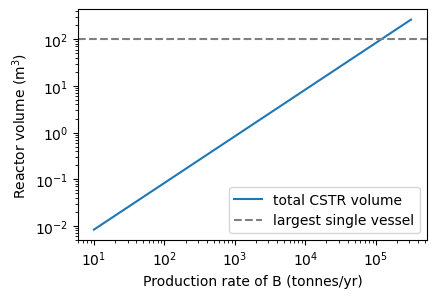

In [7]:
P_range = np.logspace(1, 5.5, 46)                          # tonnes/yr
# [... for P in P_range] is a "list comprehension": a for loop that collects each
# result into a list. np.array then turns the list into a NumPy array.
V_range = np.array([reactor_volume(P, p) for P in P_range])  # m3

plt.loglog(P_range, V_range, label="total CSTR volume")
plt.axhline(p["V_max"], color="gray", linestyle="--", label="largest single vessel")
plt.xlabel("Production rate of B (tonnes/yr)")
plt.ylabel("Reactor volume (m$^3$)")
plt.legend()
plt.show()

A straight line of slope 1: at the same residence time, volume is proportional to throughput.
**The kinetics don't know about scale.** What changes with scale is everything else: heat
removal, mixing, residence-time distribution, safety, and the largest vessel anyone will build.
Above `V_max` we need several reactors in parallel.

## 5. What changes with scale: removing the heat

The heat released is proportional to volume ($\propto L^3$), but the jacket area is only
$\propto L^2$, so the area per unit volume falls as the reactor grows. The temperature difference
needed to remove the heat through the jacket is

$$\Delta T = \frac{Q}{U A}, \qquad Q = F_B\,(-\Delta H_r) .$$

Assume each vessel is a cylinder with height $H = 1.5\,D$.

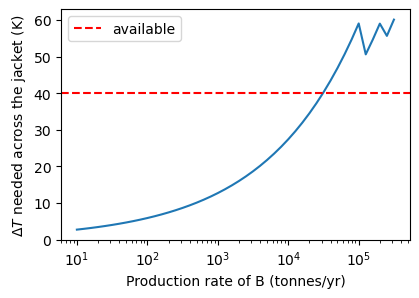

A jacket alone is not enough above about 32,000 t/yr


In [8]:
def cooling_dT(P_tonnes, p):
    """Reactor-to-coolant temperature difference (K) needed to remove the heat through the jacket."""
    V = reactor_volume(P_tonnes, p)
    n_vessels = np.ceil(V / p["V_max"])            # number of vessels in parallel
    Vi = V / n_vessels                             # volume of each, m3
    D = (4 * Vi / (1.5 * np.pi))**(1/3)            # diameter, m, from V = (pi/4) D^2 (1.5 D)
    A = np.pi * D * (1.5 * D) + np.pi * D**2 / 4   # jacketed wall + bottom, m2
    FB = P_tonnes * 1000 / p["MW"] / p["hours"] / n_vessels   # kmol/h of B made in each vessel
    Q = FB * -p["dH"] * 1000 / 3600                # heat released per vessel, W
    return Q / (p["U"] * A)

dT_range = np.array([cooling_dT(P, p) for P in P_range])

plt.semilogx(P_range, dT_range)
plt.axhline(p["dT_max"], color="red", linestyle="--", label="available")
plt.xlabel("Production rate of B (tonnes/yr)")
plt.ylabel("$\\Delta T$ needed across the jacket (K)")
plt.legend()
plt.show()

# dT_range > p["dT_max"] is an array of True/False values, one per scale.
# Indexing P_range with it keeps only the scales where the answer is True.
too_hot = P_range[dT_range > p["dT_max"]]
print(f"A jacket alone is not enough above about {round(too_hot.min(), -3):,.0f} t/yr")

At the pilot scale the jacket removes the heat with a few kelvin to spare; at plant scale it can't.
The options are internal coils, a pump-around loop through an external heat exchanger, several
smaller reactors, or a more dilute feed. **Each one is a design decision with a cost**, and none of
them showed up in the pilot plant. The drop at the right is where the volume is split between two
vessels. This kind of check is what a scale-up model is for.

## 6. Costs: capital, operating, and the minimum selling price

- **Capital.** Size the reactor by the six-tenths rule, $C = C_\text{ref}\,(V/V_\text{ref})^{n}$,
  scale up to all the equipment, then multiply by a Lang factor to get the total capital investment.
- **Annualized capital.** The capital recovery factor turns a one-off investment into an equal
  yearly payment over the plant's life, at the interest rate:
  $\text{CRF} = \dfrac{i(1+i)^N}{(1+i)^N - 1}$.
- **Operating costs.** Raw material, labor, and fixed costs proportional to the capital.
- **Minimum selling price (MSP).** The price of B at which the plant just covers all of that.

In [9]:
def capital_cost(V, p):
    """Total capital investment, $, for a total reactor volume V (m3)."""
    n_vessels = np.ceil(V / p["V_max"])                           # vessels in parallel
    reactors = n_vessels * p["C_ref"] * (V / n_vessels / p["V_ref"])**p["n_exp"]   # six-tenths rule, per vessel
    equipment = reactors / p["f_reactor"]                         # all purchased equipment
    return p["lang"] * equipment

def annual_costs(P_tonnes, p):
    """Yearly costs of the plant, $/yr, by category."""
    TCI = capital_cost(reactor_volume(P_tonnes, p), p)
    i, N = p["rate"], p["years"]
    crf = i * (1 + i)**N / ((1 + i)**N - 1)
    kg_B = P_tonnes * 1000
    return {
        "capital (annualized)": crf * TCI,
        "fixed costs": p["fixed_frac"] * TCI,
        "labor": p["labor"],
        "raw material": kg_B / p["X"] * p["price_A"],   # unreacted A is not recycled here
    }

def min_selling_price(P_tonnes, p):
    """Minimum selling price of B, $/kg."""
    # .values() gives just the numbers from the dictionary, without their names
    return sum(annual_costs(P_tonnes, p).values()) / (P_tonnes * 1000)

costs = annual_costs(P_design, p)
msp = min_selling_price(P_design, p)
TCI = capital_cost(reactor_volume(P_design, p), p)
print(f"At {P_design:,} t/yr the total capital is {TCI/1e6:.1f} M$")   # :, adds thousands commas
print(f"Minimum selling price: ${msp:.2f}/kg")
# :22s pads the text to 22 characters, :7.2f is 7 wide with 2 decimals, :.0% is a percentage
# .items() gives each name together with its value
for name, c in costs.items():
    print(f"  {name:22s} {c/1e6:7.2f} M$/yr  ({c / sum(costs.values()):.0%})")

At 50,000 t/yr the total capital is 16.6 M$
Minimum selling price: $1.19/kg
  capital (annualized)      2.18 M$/yr  (4%)
  fixed costs               1.33 M$/yr  (2%)
  labor                     0.60 M$/yr  (1%)
  raw material             55.56 M$/yr  (93%)


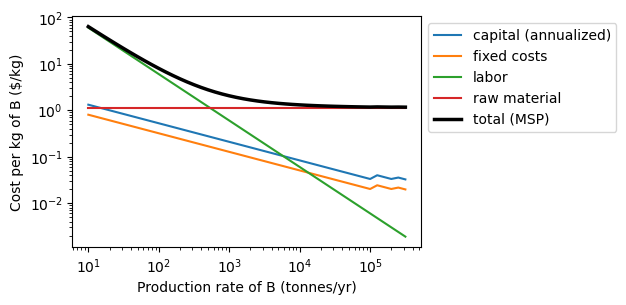

In [10]:
for name in costs:
    per_kg = [annual_costs(P, p)[name] / (P * 1000) for P in P_range]
    plt.loglog(P_range, per_kg, label=name)
plt.loglog(P_range, [min_selling_price(P, p) for P in P_range], "k", lw=2.5, label="total (MSP)")
plt.xlabel("Production rate of B (tonnes/yr)")
plt.ylabel("Cost per kg of B ($/kg)")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))   # outside the axes, so it hides no data
plt.show()

This plot is economies of scale. At small scale, labor and capital dominate, and the product costs
tens of dollars per kg. At large scale the curve flattens towards the raw-material cost divided by
the yield. From then on, **chemistry and feedstock price matter more than equipment.**

## 7. What matters most? A tornado chart

Change one input at a time to a low and a high value, and see how far the MSP moves. Sort the
inputs by how far. `q = p.copy()` makes a copy of the parameters, so changing a value in `q`
leaves the base case, `p`, alone.

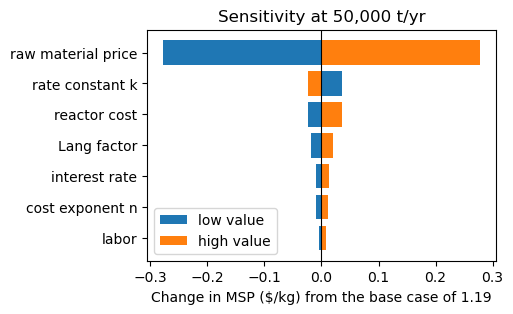

In [11]:
tests = {   # label: (parameter, low value, high value)
    "raw material price": ("price_A", 0.75, 1.25),
    "rate constant k": ("k", 3.0, 12.0),
    "reactor cost": ("C_ref", 100e3, 225e3),
    "Lang factor": ("lang", 3.5, 6.0),
    "cost exponent n": ("n_exp", 0.5, 0.7),
    "labor": ("labor", 0.4e6, 1.0e6),
    "interest rate": ("rate", 0.06, 0.15),
}
base = min_selling_price(P_design, p)
results = []
for label in tests:
    key, low, high = tests[label]     # unpack the three entries
    q = p.copy()                      # a copy, so the base case p is left alone
    q[key] = low
    msp_low = min_selling_price(P_design, q)
    q[key] = high
    msp_high = min_selling_price(P_design, q)
    results.append((label, msp_low - base, msp_high - base))

def spread(result):                               # how far the MSP moves, low to high
    label, change_low, change_high = result
    return abs(change_high - change_low)

# sort() can take a function, just as fsolve does: it calls spread() on each result
# and sorts by the answer. Smallest first, so the largest bar ends up on top.
results.sort(key=spread)

labels = [r[0] for r in results]
plt.barh(labels, [r[1] for r in results], label="low value")
plt.barh(labels, [r[2] for r in results], label="high value")
plt.axvline(0, color="k", lw=0.8)
plt.xlabel(f"Change in MSP ($/kg) from the base case of {base:.2f}")
plt.title(f"Sensitivity at {P_design:,} t/yr")
plt.legend()
plt.show()

At this scale the raw-material price swamps everything to do with equipment. That tells you where
to spend your effort: a better price quote for A would do more than refining the reactor cost
correlation. (The rate constant matters much less, because it changes only the size of the reactor, and the
reactor is a small part of the cost.)

A tornado chart is a *local*, one-at-a-time sensitivity analysis. It changes one input while the
others sit at their base values, so it cannot show interactions (an input that matters only when
another is also high), and the answer depends on the low and high values you chose. A *global*
sensitivity analysis varies all the inputs together, sampled from ranges or probability
distributions, and works out how much of the spread in the MSP each input causes, alone and through
interactions. The Python library [SALib](https://salib.readthedocs.io) does this (Sobol indices,
the Morris method and others) in a few lines, using a function like `min_selling_price`. For the
ideas behind it, see Saltelli et al., *Global Sensitivity Analysis: The Primer* (Wiley, 2008).

## 8. Optimization: the best conversion

Higher conversion wastes less A but needs a much bigger reactor, since $V \propto X/(1-X)^2$.
`minimize_scalar` finds the conversion with the lowest MSP.

Best conversion = 0.915, MSP = $1.190/kg
Base case:  X = 0.9, MSP = $1.193/kg


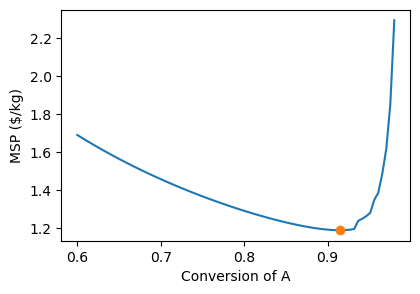

In [12]:
from scipy.optimize import minimize_scalar   # already imported at the top; repeated to show where it comes from

def msp_at_conversion(X):
    q = p.copy()
    q["X"] = X
    return min_selling_price(P_design, q)

best = minimize_scalar(msp_at_conversion, bounds=(0.5, 0.98), method="bounded")
# minimize_scalar returns a "result object": best.x is the answer, best.fun is the MSP there
print(f"Best conversion = {best.x:.3f}, MSP = ${best.fun:.3f}/kg")
print(f"Base case:  X = {p['X']}, MSP = ${base:.3f}/kg")

X_range = np.linspace(0.6, 0.98, 80)
plt.plot(X_range, [msp_at_conversion(X) for X in X_range])
plt.plot(best.x, best.fun, "o")
plt.xlabel("Conversion of A")
plt.ylabel("MSP ($/kg)")
plt.show()

The optimum is shallow: any conversion from about 0.88 to 0.93 gives an MSP within 1% of the best,
so choose within that range on other grounds (heat removal, safety, what the separation needs).
The kinks to the right are where a second, then a third, reactor vessel is added. A flat optimum
is common, and worth knowing about before you report a number to three decimal places.

In a real design you would **recycle** the unreacted A, which changes this answer completely.
Recycle makes it a flowsheet problem, and that is where Aspen, or a Python flowsheet library such
as IDAES or difflow, earns its keep. Two things to try: add the heat-removal limit from section 5 as
a constraint, and add a separation cost that rises as the conversion falls.

## Appendix: a plug-flow reactor, with `solve_ivp`

The same kinetics in a PFR. The design equation is an ODE in volume,
$\dfrac{dF_A}{dV} = -k\,C_A^2$, which `solve_ivp` integrates. An *event* stops the integration
when the target conversion is reached.

`solve_ivp` is written for *systems* of ODEs, so even with one equation the state `y` is a list
(here `y[0]` is $F_A$), and the function returns a list of derivatives. The function also uses
`v0` and `p` from outside it, which works but means it depends on whatever those were last set to.

PFR volume 4.2 m3, against 41.7 m3 for a CSTR


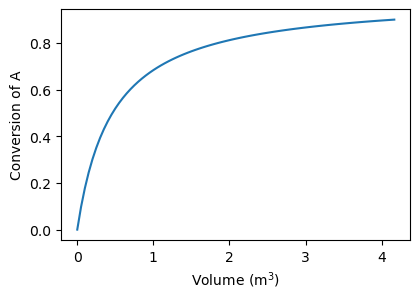

In [13]:
from scipy.integrate import solve_ivp   # already imported at the top; repeated to show where it comes from

FA0 = P_design * 1000 / p["MW"] / p["hours"] / p["X"]   # kmol/h of A
v0 = FA0 / p["CA0"]                                     # m3/h

def pfr(V, y):
    FA = y[0]
    CA = FA / v0
    return [-p["k"] * CA**2]

def reached_target(V, y):
    return y[0] - FA0 * (1 - p["X"])     # zero when the conversion reaches X
reached_target.terminal = True           # unusual Python: a setting stored on the function itself,
                                         # which is how solve_ivp is told to stop at this event

sol = solve_ivp(pfr, (0, 1000), [FA0], events=reached_target, max_step=0.05)
V_pfr = sol.t_events[0][0]    # t_events has one array per event function: first event, first time
print(f"PFR volume {V_pfr:.1f} m3, against {reactor_volume(P_design, p):.1f} m3 for a CSTR")

plt.plot(sol.t, 1 - sol.y[0] / FA0)      # sol.t: the volumes; sol.y[0]: F_A at each one
plt.xlabel("Volume (m$^3$)")
plt.ylabel("Conversion of A")
plt.show()

For a second-order reaction at 90% conversion, the PFR is a tenth the size of the CSTR.

## Where next

- **[pycse](https://kitchingroup.cheme.cmu.edu/pycse/intro.html)**, John Kitchin's free book,
  *Python Computations in Science and Engineering*. Every chapter opens in Colab. Most relevant:
  [nonlinear equations](https://kitchingroup.cheme.cmu.edu/pycse/book/07-nla-1.html),
  [systems of ODEs](https://kitchingroup.cheme.cmu.edu/pycse/book/04-fode-2.html),
  [optimization](https://kitchingroup.cheme.cmu.edu/pycse/book/10-min-max.html),
  [constrained optimization](https://kitchingroup.cheme.cmu.edu/pycse/book/13-constrained-optimization.html),
  [nonlinear regression](https://kitchingroup.cheme.cmu.edu/pycse/book/11-regression.html).
- The [README for this repository](https://github.com/NUChemE/capstone-python) lists which tool to
  use for which problem, and how to install Python on your own computer.

---

*About this notebook.* Planned by Richard West. The code and text were mostly written by
Claude Code (Opus 5.5), an AI assistant, and checked by running every cell. All the numbers are
illustrative placeholders. MIT licence.